# Hierarchical Clustering in Machine Learning

Hierarchical Clustering is an unsupervised machine learning algorithm that groups similar data points into clusters. Unlike classification or regression, it does not require a target column such as Survived, Price, or Left.

1. What is Hierarchical Clustering?

Suppose a shopping company has customer data containing age, annual income, and spending score. It wants to group customers into segments such as:
- Customers who spend a lot.
- Customers with average spending.
- Customers who spend very little.


Hierarchical clustering groups similar customers based on their features.

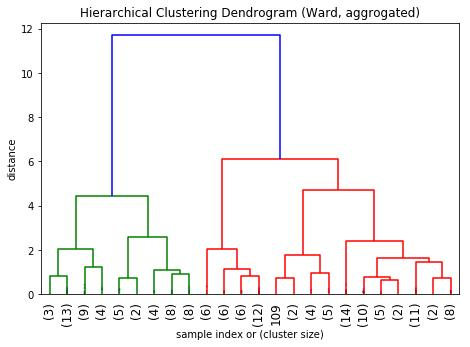

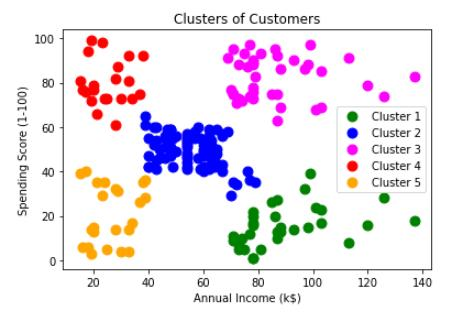

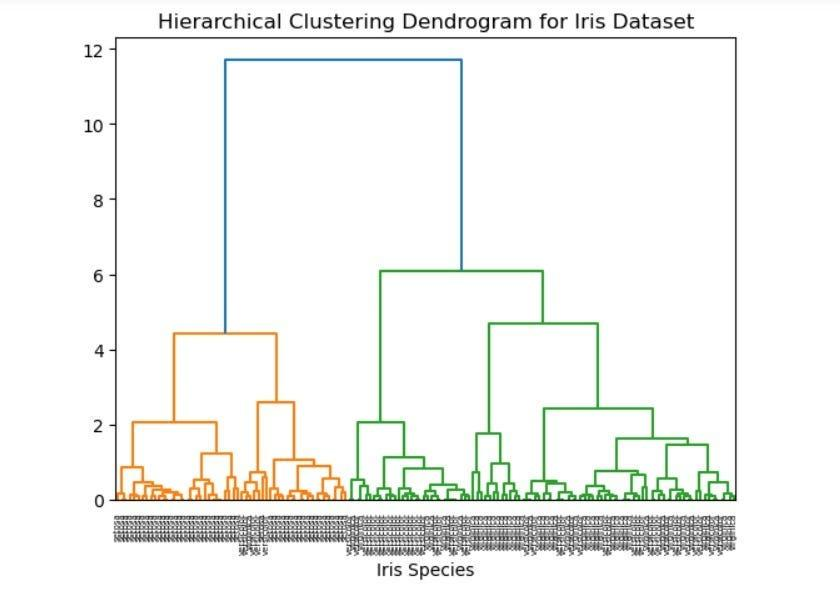

How it works
1. Calculate the distance between data points.
2. Find the closest points or clusters.
3. Merge the closest clusters in agglomerative clustering.
4. Repeat until all points belong to one cluster, or until a chosen stopping condition is met.
5. Use a dendrogram to decide how many clusters to create.

2. Types of Hierarchical Clustering

There are two main approaches.

1. Agglomerative clustering (bottom-up)

Starts with every data point as an individual cluster and repeatedly merges the closest clusters. This is the most commonly used approach in scikit-learn.

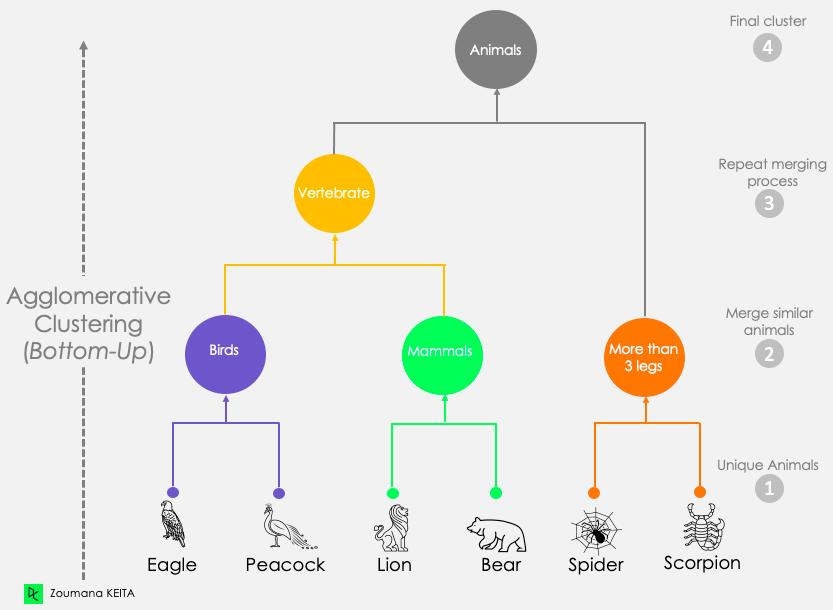

2. Divisive clustering (top-down)


Starts with all data points in one cluster and repeatedly splits clusters into smaller groups. It is less commonly used in standard scikit-learn workflows.

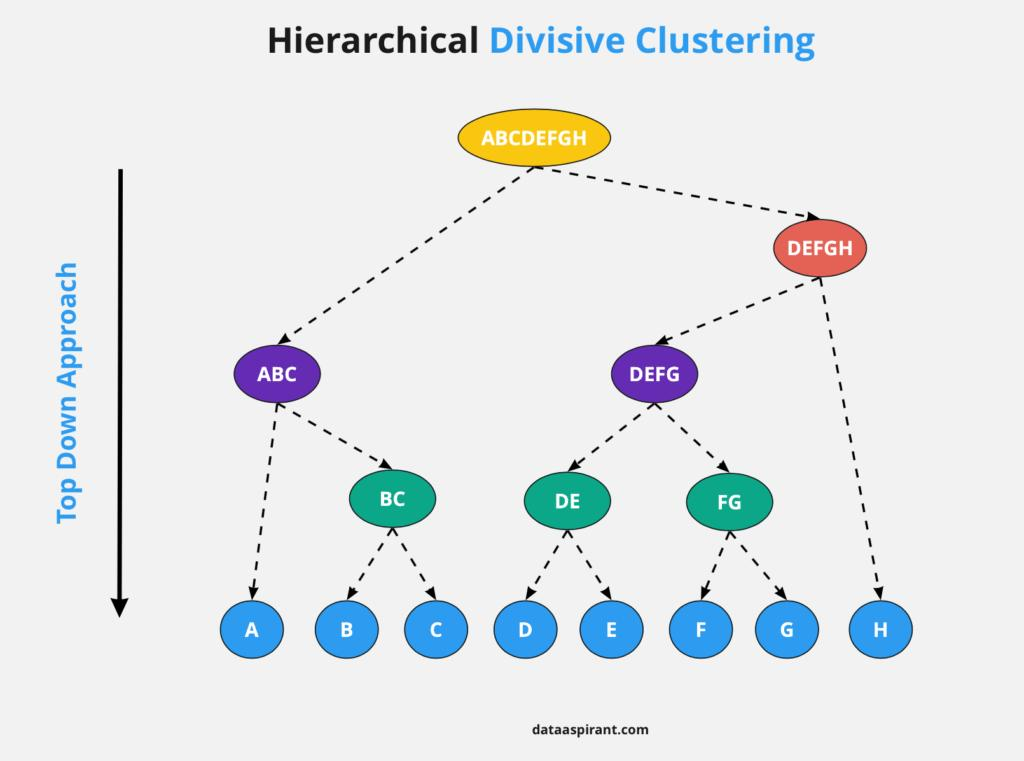

# Linkage methods
Linkage determines the distance between two clusters.

|Linkage	|How it measures distance	|Typical use
:-----------|---------------------------|-----------
single|	Closest pair of points	|Detecting connected shapes; can cause chaining
complete|	Farthest pair of points	|Compact, separated clusters
average|	Average pairwise distance	|Balanced general-purpose clustering
ward|	Increase in within-cluster variance	|Compact clusters with numeric, scaled features

Important: ward linkage works with Euclidean distance and is often a good starting point for numerical customer or employee data.

3. Complete ML workflow architecture

Hierarchical clustering is unsupervised, so it does not train against a known target label. You can still split the data for exploratory stability checks, but a standard train/test split is not required in the same way as supervised learning.

What and why are we doing each step?

|Step	|Purpose
:-------|-------
Problem understanding|	Decide what you want to group, such as customers or products.
Load dataset|	Read CSV or other data into pandas.
Understand dataset|	Inspect columns, data types, duplicates, and descriptive statistics.
Data cleaning|	Handle missing values, invalid values, and duplicates.
EDA and visualization|	Discover distributions, relationships, and outliers.
Feature engineering|	Select useful numerical features and encode categories when appropriate.
Train/test split|	Optional for checking whether cluster patterns remain stable on held-out data.
Feature scaling|	Prevent features with large numerical ranges from dominating distance calculations.
Dendrogram	Visualize| which clusters merge and at what distance.
Select clusters|	Choose a useful cut level and assess cluster quality.
Fit the model|	Apply AgglomerativeClustering.
Evaluate|	Use silhouette score and business interpretation; no true labels are required.
Save/deploy|	Store cluster assignments, preprocessing steps, and the clustering model configuration.

4. Python libraries you need

Install the libraries in your VS Code terminal or Jupyter notebook:

In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn scipy

# Library	Why we use it
:-----|--------------------------------------
|-----|-------------------------------------
NumPy|	Generate and manipulate numerical data.
pandas|	Load, clean, and analyze datasets.
Matplotlib|	Draw plots and dendrograms.
Seaborn|	Create heatmaps and statistical visualizations.
scikit-learn|	Scale features, build clusters, and evaluate results.
SciPy|	Calculate hierarchical linkages and draw dendrograms.

5. Example 1 — Customer segmentation

**Problem statement:** A shopping company wants to segment customers according to annual income and spending score.

This first example demonstrates the complete workflow, including data cleaning, EDA, visualization, scaling, dendrogram, clustering, evaluation, and saving the results.

File: example1_customer_segmentation.py — the code runs without an external dataset.

In [4]:

# ============================================
# EXAMPLE 1: CUSTOMER SEGMENTATION
# Hierarchical Clustering - Complete ML Workflow
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score


In [5]:

# 1. Create a sample customer dataset
np.random.seed(42)

customers = pd.DataFrame({
    "Annual_Income": np.random.randint(15, 130, 100),
    "Spending_Score": np.random.randint(1, 100, 100),
    "Age": np.random.randint(18, 65, 100)
})


In [6]:

# 2. Understand the dataset
print("\nFirst five rows:")
print(customers.head())

print("\nDataset information:")
print(customers.info())

print("\nStatistical summary:")
print(customers.describe())

print("\nMissing values:")
print(customers.isnull().sum())

print("\nDuplicate rows:", customers.duplicated().sum())



First five rows:
   Annual_Income  Spending_Score  Age
0            117              48   45
1             66              15   42
2            107              72   56
3             29              78   50
4            121              87   18

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Annual_Income   100 non-null    int32
 1   Spending_Score  100 non-null    int32
 2   Age             100 non-null    int32
dtypes: int32(3)
memory usage: 1.3 KB
None

Statistical summary:
       Annual_Income  Spending_Score         Age
count     100.000000      100.000000  100.000000
mean       71.050000       48.950000   39.130000
std        33.543391       29.122304   13.416148
min        16.000000        1.000000   18.000000
25%        42.500000       27.750000   26.000000
50%        74.000000       45.000000   41.000000
75%   

In [7]:

# 3. Clean the dataset
customers = customers.drop_duplicates()

features = ["Annual_Income", "Spending_Score"]
X = customers[features].copy()


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


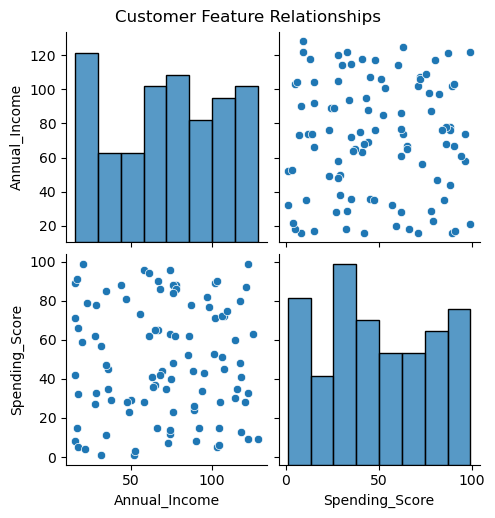

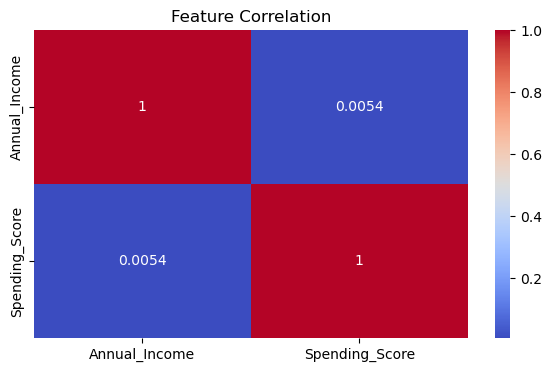

In [8]:

# Handle missing values if they exist
X = X.fillna(X.median())

# 4. EDA and visualization
sns.pairplot(customers[features])
plt.suptitle("Customer Feature Relationships", y=1.02)
plt.show()

plt.figure(figsize=(7, 4))
sns.heatmap(customers[features].corr(),
            annot=True, cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()


In [ ]:

# 5. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


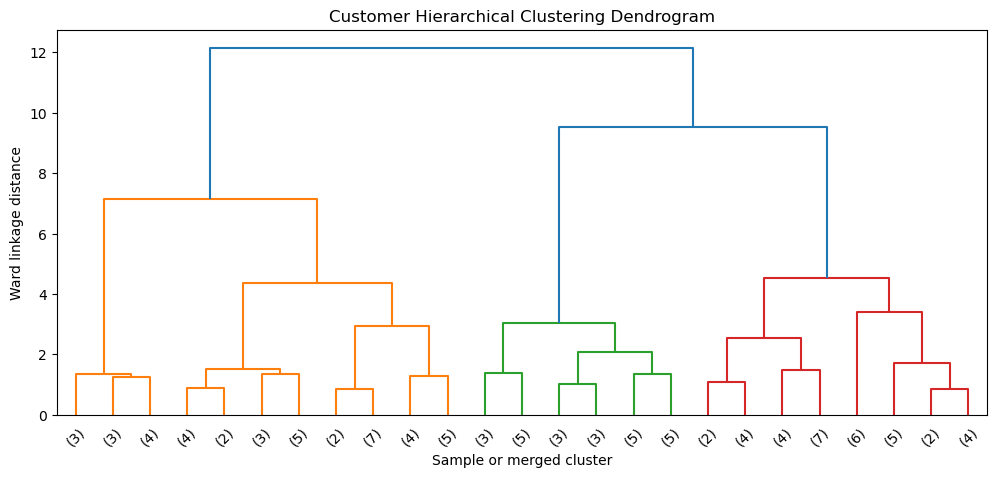

In [9]:

# 6. Create a dendrogram
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=25)
plt.title("Customer Hierarchical Clustering Dendrogram")
plt.xlabel("Sample or merged cluster")
plt.ylabel("Ward linkage distance")
plt.show()


In [10]:

# 7. Fit the clustering model
model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

customers["Cluster"] = model.fit_predict(X_scaled)


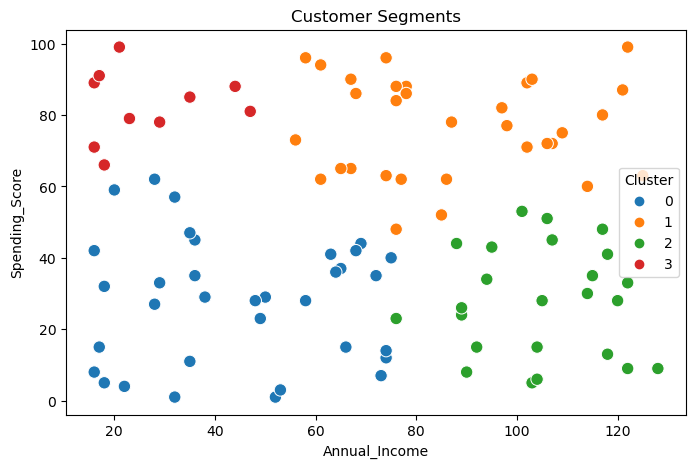

In [11]:

# 8. Visualize clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=customers,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="tab10",
    s=80
)
plt.title("Customer Segments")
plt.show()


In [12]:

# 9. Evaluate clustering
score = silhouette_score(X_scaled, customers["Cluster"])
print("\nSilhouette Score:", round(score, 3))



Silhouette Score: 0.372


In [13]:

# 10. Understand the clusters
print("\nCustomer segment profiles:")
print(customers.groupby("Cluster")[features].mean().round(2))

print("\nCustomers per cluster:")
print(customers["Cluster"].value_counts().sort_index())



Customer segment profiles:
         Annual_Income  Spending_Score
Cluster                               
0                44.97           27.85
1                87.28           76.72
2               104.88           27.75
3                26.60           82.70

Customers per cluster:
Cluster
0    34
1    32
2    24
3    10
Name: count, dtype: int64


In [14]:

# 11. Save results
customers.to_csv("customer_clusters.csv", index=False)
print("\nSaved: customer_clusters.csv")



Saved: customer_clusters.csv


Step-by-step explanation

1. Dataset creation: We create 100 sample customers with income, spending score, and age.
2. Dataset inspection: head(), info(), and describe() reveal the dataset's structure and distribution.
3. Data cleaning: Duplicates are removed and missing feature values are filled using medians.
4. EDA: Pair plots show feature relationships, and a heatmap shows correlations.
5. Scaling: StandardScaler() transforms the selected features to comparable scales.
6. Dendrogram: linkage(..., method="ward") calculates the hierarchy of merges.
7. Model building: n_clusters=4 requests four clusters. This is an example choice, not necessarily the optimal number.
8. Visualization: The scatter plot shows the four groups.
9. Evaluation: The silhouette score measures how separated the clusters are.
10. Interpretation: Group averages reveal the characteristics of each segment.
11. Saving: to_csv() saves each customer's cluster assignment.

Important: This is synthetic data. It demonstrates the workflow, but real customer segments should be validated with actual data and business context.

6. How to choose the number of clusters

A dendrogram helps you decide where to cut the hierarchy.

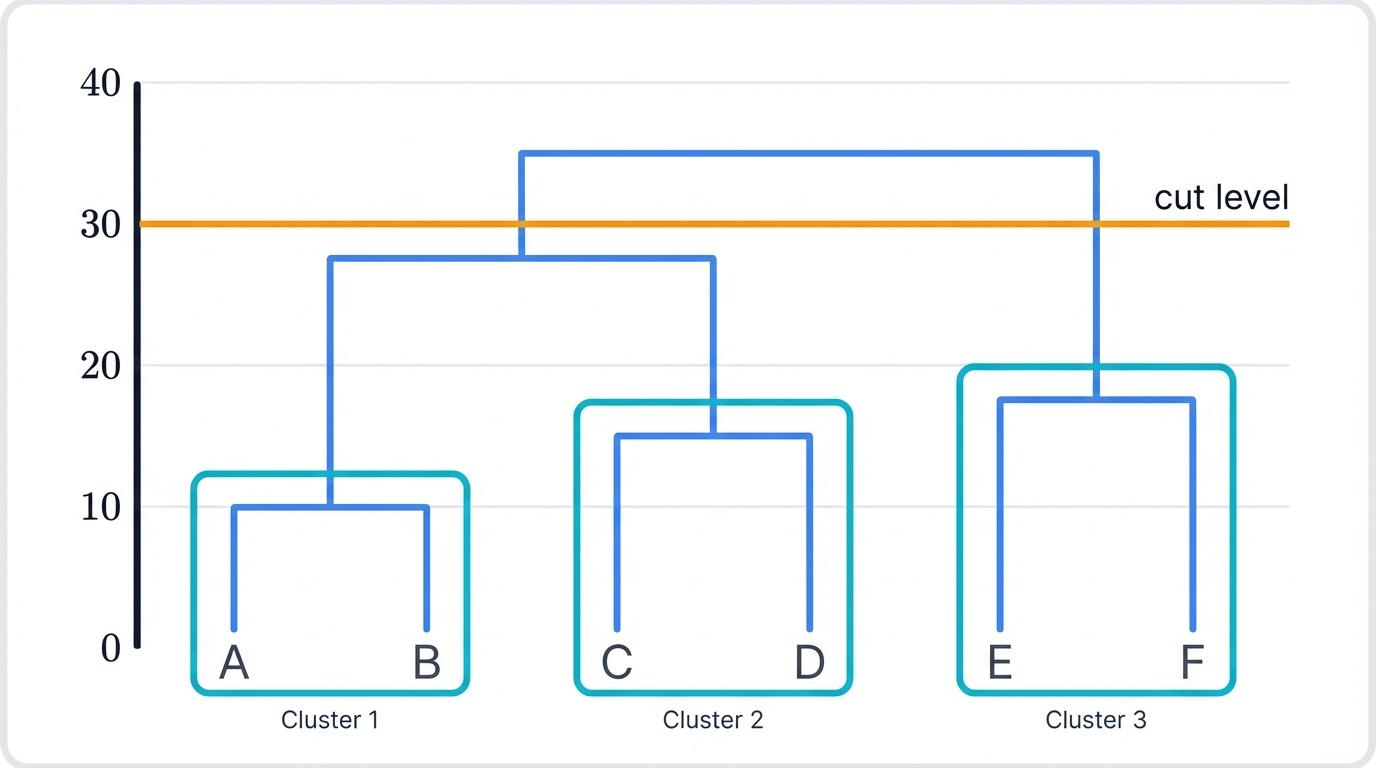

Look for a relatively large vertical gap between merge heights. A horizontal cut through that gap can separate groups before they merge into larger clusters.


You can also compare silhouette scores for several choices of cluster count.

Clusters: 2, Silhouette Score: 0.343
Clusters: 3, Silhouette Score: 0.363
Clusters: 4, Silhouette Score: 0.372
Clusters: 5, Silhouette Score: 0.346
Clusters: 6, Silhouette Score: 0.352
Clusters: 7, Silhouette Score: 0.374


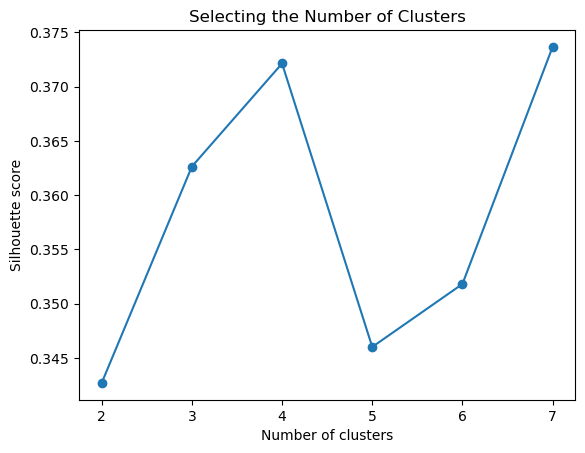

In [3]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scores = []

for k in range(2, 8):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.3f}")

plt.plot(range(2, 8), scores, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Selecting the Number of Clusters")
plt.xticks(range(2, 8))
plt.show()


8. Example 3 — Employee analytics

**Problem statement:** An HR team wants to group employees according to working hours, performance score, and years of experience.

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram


In [16]:

# 1. Create sample employee data
np.random.seed(10)
df = pd.DataFrame({
    "Working_Hours": np.random.randint(25, 61, 120),
    "Performance": np.random.uniform(1, 5, 120).round(2),
    "Experience": np.random.randint(0, 21, 120)
})


In [17]:

# 2. Inspect and clean
print(df.head())
print(df.describe())
print(df.isnull().sum())

df = df.drop_duplicates()
features = ["Working_Hours", "Performance", "Experience"]
X = df[features].fillna(df[features].median())


   Working_Hours  Performance  Experience
0             34         4.42           5
1             40         1.27          19
2             25         2.86          11
3             53         4.13          10
4             50         3.87           6
       Working_Hours  Performance  Experience
count     120.000000   120.000000  120.000000
mean       43.558333     2.855333   10.383333
std         9.481336     1.131227    6.443267
min        25.000000     1.060000    0.000000
25%        36.000000     1.777500    5.000000
50%        43.000000     2.870000   11.000000
75%        52.000000     3.890000   16.000000
max        60.000000     4.910000   20.000000
Working_Hours    0
Performance      0
Experience       0
dtype: int64


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


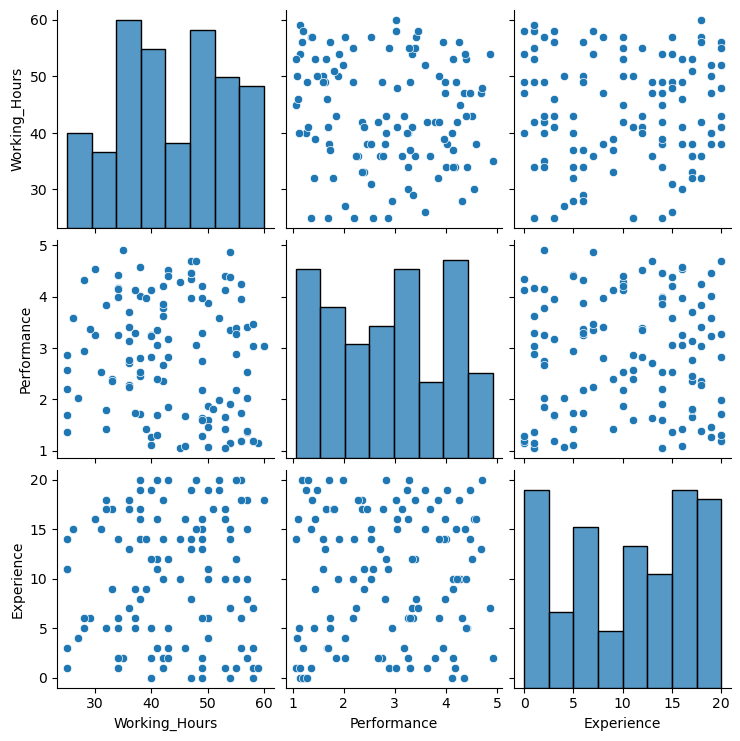

In [18]:

# 3. EDA
sns.pairplot(df[features])
plt.show()


In [19]:

# 4. Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



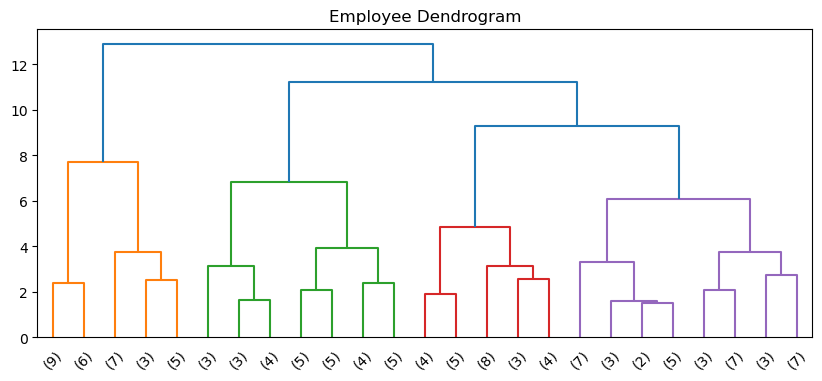

In [20]:
# 5. Dendrogram
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=25)
plt.title("Employee Dendrogram")
plt.show()


In [21]:

# 6. Cluster employees
model = AgglomerativeClustering(
    n_clusters=3, linkage="ward"
)
df["Cluster"] = model.fit_predict(X_scaled)


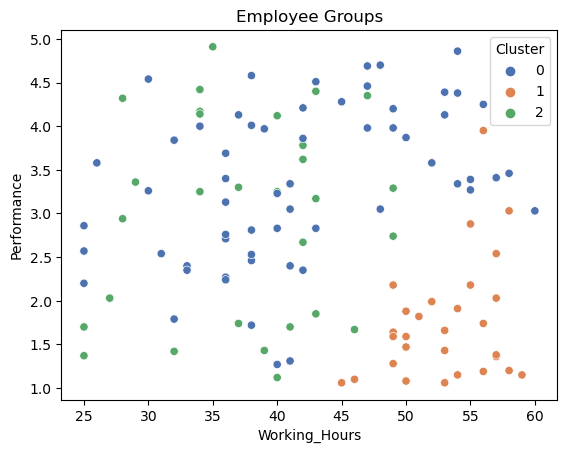

In [22]:

# 7. Visualize
sns.scatterplot(
    data=df, x="Working_Hours",
    y="Performance", hue="Cluster",
    palette="deep"
)
plt.title("Employee Groups")
plt.show()


In [23]:

# 8. Evaluate and interpret
print("Silhouette:",
      round(silhouette_score(X_scaled, df["Cluster"]), 3))

print(df.groupby("Cluster")[features].mean().round(2))


Silhouette: 0.242
         Working_Hours  Performance  Experience
Cluster                                        
0                41.74         3.36       14.21
1                53.20         1.72        9.40
2                37.41         2.97        3.34


In [24]:

# 9. Save
df.to_csv("employee_clusters.csv", index=False)


**Interpretation:** You might discover groups with different working hours, performance levels, or experience. These are synthetic records, so they should not be used to make real HR decisions. In particular, longer working hours do not necessarily indicate better performance.

9. Example 4 — E-commerce product grouping

Problem statement: An online store wants to group products by price, monthly sales, and customer ratings.

In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram


In [26]:

# 1. Create sample product data
np.random.seed(25)
df = pd.DataFrame({
    "Price": np.random.randint(100, 5000, 100),
    "Monthly_Sales": np.random.randint(5, 500, 100),
    "Rating": np.random.uniform(1, 5, 100).round(1)
})


In [27]:

# 2. Inspect and clean
print(df.head())
print(df.describe())
print(df.isnull().sum())

features = ["Price", "Monthly_Sales", "Rating"]
X = df[features].fillna(df[features].median())


   Price  Monthly_Sales  Rating
0    418             25     4.1
1   2291            106     1.5
2   3034            104     4.7
3    355            388     1.7
4   1275            325     2.8
             Price  Monthly_Sales      Rating
count   100.000000     100.000000  100.000000
mean   2522.960000     266.070000    2.970000
std    1482.140316     144.761752    1.093923
min     114.000000      13.000000    1.200000
25%    1245.000000     133.750000    2.100000
50%    2533.500000     275.500000    2.900000
75%    3872.000000     388.000000    3.825000
max    4979.000000     492.000000    5.000000
Price            0
Monthly_Sales    0
Rating           0
dtype: int64


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


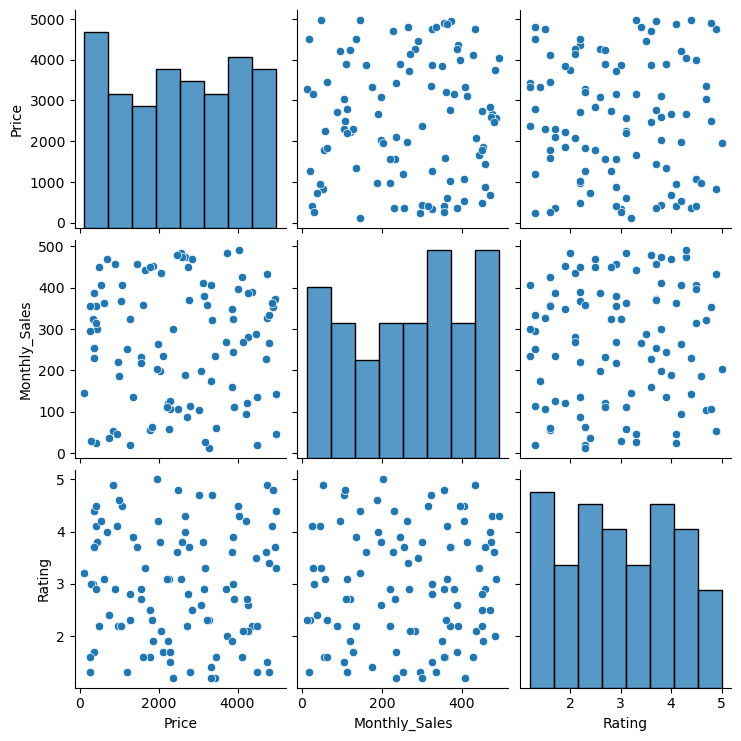

In [28]:

# 3. EDA
sns.pairplot(df[features])
plt.show()


In [29]:

# 4. Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


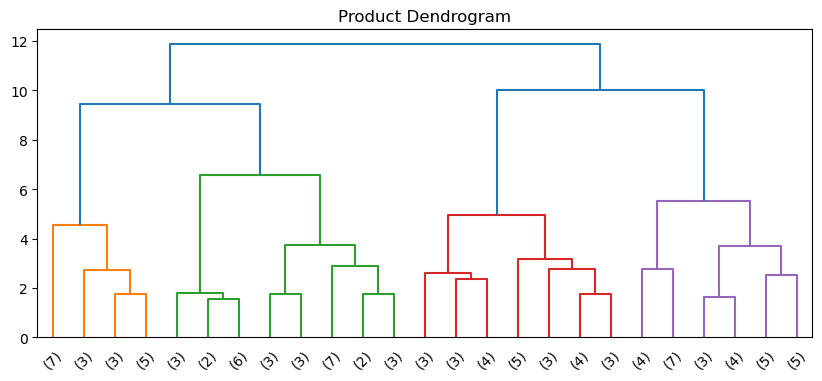

In [30]:

# 5. Dendrogram
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=25)
plt.title("Product Dendrogram")
plt.show()


In [31]:

# 6. Build clusters
model = AgglomerativeClustering(
    n_clusters=4, linkage="ward"
)
df["Cluster"] = model.fit_predict(X_scaled)


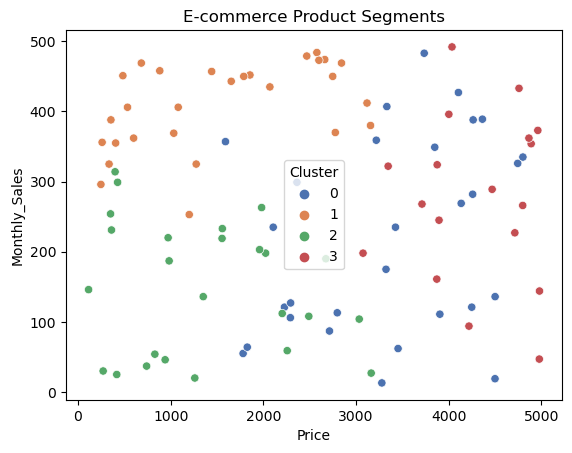

In [32]:

# 7. Visualize
sns.scatterplot(
    data=df, x="Price", y="Monthly_Sales",
    hue="Cluster", palette="deep"
)
plt.title("E-commerce Product Segments")
plt.show()


In [33]:

# 8. Evaluate
print("Silhouette:",
      round(silhouette_score(X_scaled, df["Cluster"]), 3))


Silhouette: 0.264


In [34]:

# 9. Analyze groups
print(df.groupby("Cluster")[features].mean().round(2))


           Price  Monthly_Sales  Rating
Cluster                                
0        3359.24         222.41    1.83
1        1540.36         408.82    2.92
2        1372.52         148.60    3.71
3        4301.94         277.50    3.86


In [35]:

# 10. Save
df.to_csv("product_clusters.csv", index=False)


**Interpretation:** The groups may reveal high-priced products, low-priced products, strong sellers, or products with different rating profiles. The actual meaning depends on the group averages rather than the cluster IDs.

10. Example 5 — Compare linkage methods

Problem statement: Find out how single, complete, average, and ward linkage affect cluster formation on the same dataset.

This example uses a two-moons dataset, where groups have curved shapes. It demonstrates why linkage choice matters.

In [36]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram


In [37]:

# 1. Generate a nonlinear dataset
X, _ = make_moons(
    n_samples=300, noise=0.07, random_state=42
)


In [38]:

# 2. Scale features
X_scaled = StandardScaler().fit_transform(X)


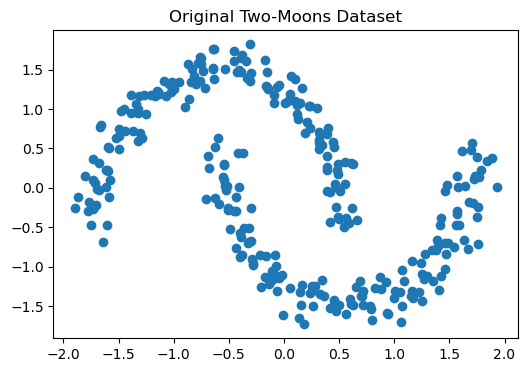

In [39]:

# 3. Visualize original data
plt.figure(figsize=(6, 4))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1])
plt.title("Original Two-Moons Dataset")
plt.show()


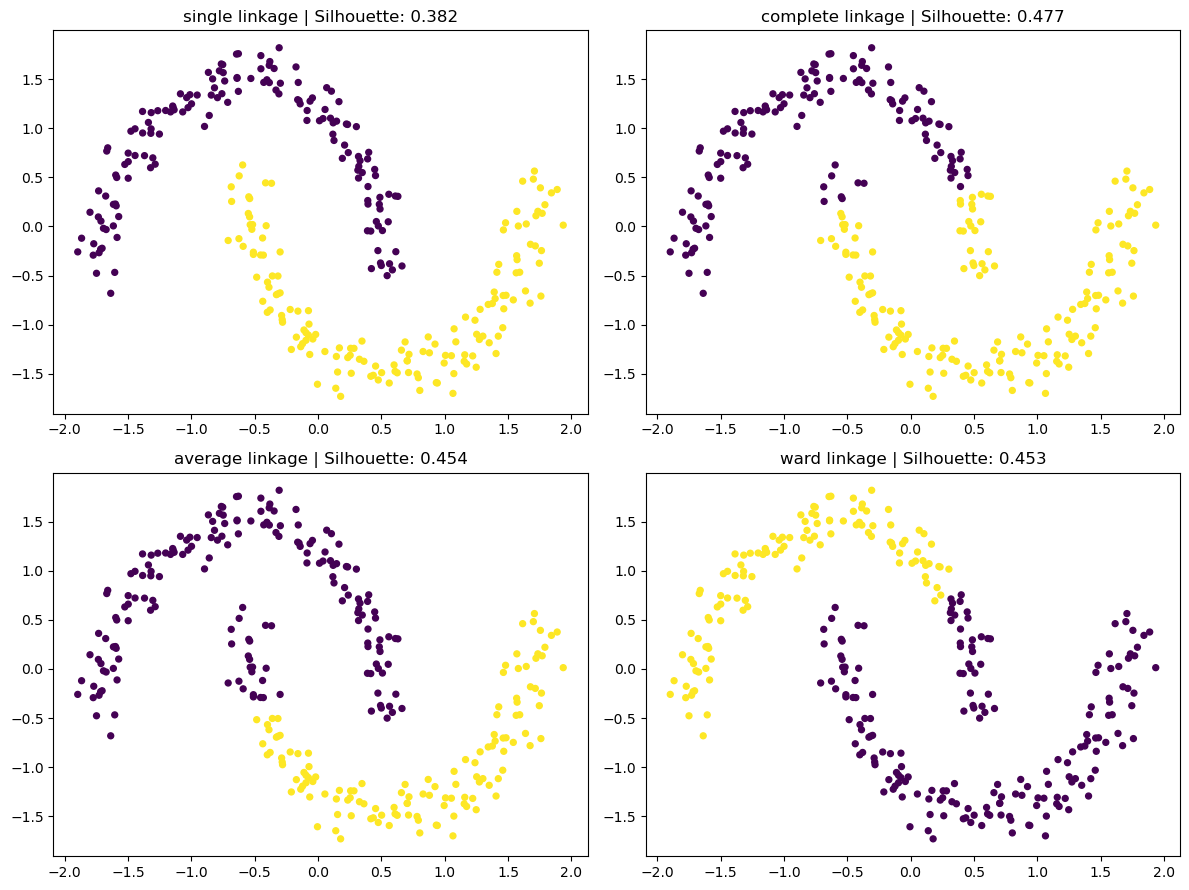

In [40]:

# 4. Compare linkage methods
methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for method, ax in zip(methods, axes.flat):
    model = AgglomerativeClustering(
        n_clusters=2, linkage=method
    )
    labels = model.fit_predict(X_scaled)

    ax.scatter(
        X_scaled[:, 0], X_scaled[:, 1],
        c=labels, cmap="viridis", s=18
    )
    score = silhouette_score(X_scaled, labels)
    ax.set_title(f"{method} linkage | Silhouette: {score:.3f}")

plt.tight_layout()
plt.show()


In [41]:

# 5. Compare scores
for method in methods:
    model = AgglomerativeClustering(
        n_clusters=2, linkage=method
    )
    labels = model.fit_predict(X_scaled)
    print(
        f"{method:10s}: "
        f"{silhouette_score(X_scaled, labels):.3f}"
    )


single    : 0.382
complete  : 0.477
average   : 0.454
ward      : 0.453


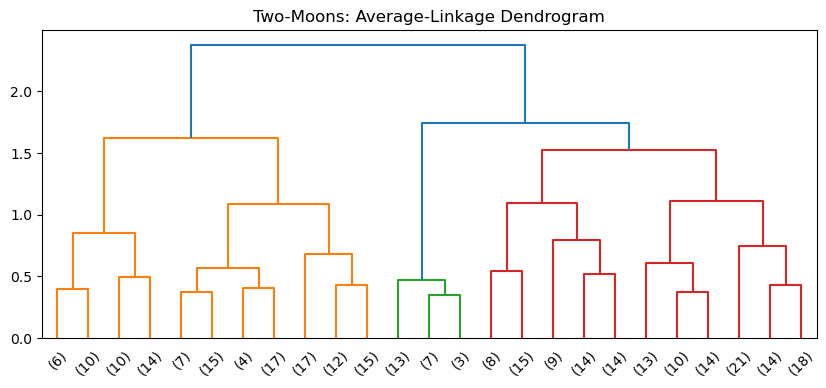

In [42]:

# 6. Inspect a dendrogram for average linkage
Z = linkage(X_scaled, method="average")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=25)
plt.title("Two-Moons: Average-Linkage Dendrogram")
plt.show()


What to observe:
- single can preserve connected, curved shapes but is vulnerable to chaining.
- complete tends to favor compact, separated clusters.
- average uses average pairwise distance and is a useful comparison.
- ward favors compact groups and may split curved shapes in ways that do not match their natural structure.

For this nonlinear dataset, don't select a linkage method using silhouette score alone. Also inspect the plots and consider whether the algorithm captures the shape you are trying to discover.

11. How to use train/test split with Hierarchical Clustering

This is an important difference between supervised and unsupervised learning.

In classification, you train using X_train, y_train and evaluate predictions using X_test, y_test. Hierarchical clustering has no target variable and standard agglomerative clustering does not provide a normal predict() method for unseen data.

You can split data to check whether groups remain stable, or compare cluster assignments on held-out data using a defined procedure. However, the following is not a conventional train/test evaluation:

In [43]:
from sklearn.model_selection import train_test_split

# X_scaled should contain cleaned and scaled features
X_train, X_test = train_test_split(
    X_scaled,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 240
Testing records: 60


For a rigorous stability analysis, fit clustering independently on training and test subsets, or use a suitable resampling-based procedure. Fit preprocessing transformations on the training data when assessing held-out stability. Since the cluster IDs are arbitrary, compare the resulting partitions rather than assuming cluster 0 in one fit is equivalent to cluster 0 in another.

12. Common mistakes to avoid

- Not scaling features: Income or price can dominate smaller-scale variables.
- Choosing the number of clusters arbitrarily: Use the dendrogram, silhouette score, and domain knowledge together.
- Using inappropriate linkage: Different linkage methods can produce very different results.
- Treating cluster IDs as rankings: Cluster 2 is not necessarily better than cluster 1.
- Assuming clusters are ground truth: Clusters are patterns found by an algorithm, not guaranteed natural categories.
- Using predict() with AgglomerativeClustering: The standard estimator does not support assigning new samples through a normal prediction method.

- Ignoring computation cost: Exact hierarchical clustering can become expensive as the number of records grows.

# 13. Hierarchical Clustering vs. K-Means vs. DBSCAN

|Feature	|Hierarchical	|K-Means	|DBSCAN
:-----------|---------------|-----------|-------
Learning type	|Unsupervised	|Unsupervised	|Unsupervised
Number of clusters|	Can be selected from dendrogram or set directly	|Must specify k	|Not specified directly
Dendrogram|	Yes|	No|	No
Cluster shapes|	Depends on linkage|	Usually compact|	Can find irregular shapes
Outlier handling|	No dedicated noise label|	No dedicated noise label|	Can label noise as -1
Typical use|	Hierarchical group discovery|	Large-scale segmentation|	Density-based grou

## 14. Practice assignments

1. Retail customer segmentation

Use annual income, spending score, and age. Compare 3, 4, and 5 clusters.

2. Student performance grouping

Group students using study hours, attendance, and exam scores. Interpret the cluster profiles.

3. Employee analytics

Group employees using experience, performance, and working hours. Compare Ward and average linkage.

4. E-commerce product segmentation

Group products by price, sales volume, and ratings. Identify high-sales and low-sales groups.

5. Linkage comparison

Apply single, complete, average, and Ward linkage to the same dataset. Compare plots and silhouette scores.

**recommendation:** Start with Example 1 and understand scaling, linkage, dendrograms, and silhouette scores. Then run Example 5 to see how the choice of linkage changes the resulting clusters. These concepts form the foundation for applying hierarchical clustering to real-world ML projects.